# 2 · Scoring: tying a tracked signal to a satellite

**Goal.** Given what detection and tracking store for every signal (start, end, centre frequency, 1 s frequency
bins), decide which catalog object transmits on each channel: with few false identifications, as early as the
evidence allows, never from one doubtful track, and without ever holding silence against a satellite.

**Method in one paragraph.** Detections are grouped into channels by frequency and into sessions by pass. For every
session, every catalog object that was above the horizon throughout gets two likelihood ratios: a *timing* one (how
rarely would this object be up for a signal of this length) and a *Doppler* one (how much better does its predicted
curve fit the track than random other satellites do, and than an orbit fitted freely to the track does), after a
robust fit that gives the transmitter an unknown rest frequency, drift, wander, steps and the turn-off droop. Per
channel, the sessions are explained as a mixture of transmitters (catalog objects, an unknown satellite, a
non-satellite), and each candidate's **campaign score** is how much the channel is better explained with it than
without it. A candidate is declared when the score passes ln(N/α), three sessions support it, Doppler alone confirms
it and the signal was not repeatedly heard while it was just out of view.

**Data.** No IQ: 14 days of ASSIST truth for 60 transmitters on catalog orbits, passed through an emulator of the
detector and tracker of notebooks 0 and 1 with keying, eclipses, unstable oscillators, the droop of `droop.png`, bad
bins and catalog error. 360 simulated channel-campaigns, 28 000 sessions.

**Summary of results** — details in [section 8](#8--findings-and-open-points).

- **Transmitter in the catalog: no false identification in 210 channels**, and identification after a median of
  3–4 sessions (within one or two days) for a transmitter alone on its channel, 10 sessions on a shared channel.
- **Transmitter not in the catalog: 2 false identifications in 96 channels**, both pinned on a neighbour one to two
  minutes away in the same train, both with weak Doppler. With a companion less than a minute away the companion is
  named; that case cannot be told apart from here.
- **Least-squares scoring (dopplerguesser) is not usable**: 34 % of 90 s tracks are misidentified with 3 % bad bins,
  and an ALOUETTE-like oscillator makes it reject the true satellite in 83 % of sessions. The robust fit with a
  transmitter model brings that to 5 %.
- **A 20 s track cannot decide** (true satellite not first in 20 % of them); its Doppler evidence comes out near 1
  by itself, so it contributes timing only.
- **Most catalog objects do not fly alone.** Of 51 objects drawn at random from the candidate catalog, only 14 have
  no other catalog object within five minutes (the five known zombies all do fly alone). Neighbours, not chance
  coincidences, are what limits identification, and they are what three of the four tests in the decision rule
  exist for.

Contents: 1 candidates · 2 campaign simulator · 3 fine pipeline (Doppler) · 4 coarse pipeline (timing) · 5 fusion ·
6 decision rule · 7 a campaign end to end · 8 findings and open points.

Code is in [2_scoring_lib.py](2_scoring_lib.py) (loaded as `L`). Results are cached in `out/scoring/`; with the caches
the notebook runs in under a minute, from scratch in about 100 min on 6 cores (10 of them for ASSIST's truth).

In [1]:
import importlib
import pickle
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from cycler import cycler

L = importlib.import_module("2_scoring_lib")

# series colours in a fixed order (blue, orange, aqua, yellow, magenta, green, violet, red); grid and axes recessive
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.grid": True,
    "grid.color": "#e8e7e2", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 5, "axes.prop_cycle": cycler(color=COL), "font.size": 10,
    "axes.titlesize": 10.5, "legend.frameon": False, "figure.dpi": 110,
})  # fmt: skip


def cached(name, fn):
    """Run fn once and keep its result in out/scoring/<name>.pkl (delete the file to recompute)."""
    f = L.OUT / f"{name}.pkl"
    if f.exists():
        return pickle.load(f.open("rb"))
    t = time.time()
    r = fn()
    pickle.dump(r, f.open("wb"))
    print(f"[{name}: computed in {time.time() - t:.0f} s]")
    return r


t = time.time()
C = L.ctx()  # catalog, pass table, decoy library and ASSIST truth; built on first use (~10 min), cached afterwards
ISOLATED = [n for n in C.pool if not C.companions[n]]  # pool transmitters without a companion less than a minute away
KIND = {n: "companions" if C.companions[n] else "train" if C.train[n] else "isolated" for n in C.pool}
print(f"context ready in {time.time() - t:.0f} s: {len(C.cat)} candidates, {len(C.pt.aos)} passes, "
      f"{len(C.pool)} pool transmitters with {sum(len(v) for v in C.truth.values())} true passes")

context ready in 2 s: 4321 candidates, 451793 passes, 60 pool transmitters with 6514 true passes


## 1 · Candidates

**Element sets.** OMM files from retlector (`active` + `satnogs`, snapshot of 2026-11-14) are loaded into an
`ElementStore` that keeps every element set per NORAD id. `ElementStore.nearest(norad, t)` returns the set whose epoch
is closest to `t`; a detection is always scored with that set, never with "the latest". With one snapshot on disk the
rule is trivial here; with a GP history from space-track it is the same call.

**Multi-stage filter** (dopplerguesser's): drop Starlink and OneWeb by name, debris and rocket bodies by name, objects
slower than 6 rev/day (GEO, MEO) and eccentricity above 0.25. What remains is the candidate catalog.

**Visibility.** A pass table (AOS, LOS of every candidate over the 14 campaign days, flat 0° horizon) is built once.
A candidate is kept for a signal only if one of its passes contains the *whole* signal, with 5 s forgiven at each end
for element error and the horizon.

**Predicted Doppler.** SGP4 → TEME; the station is rotated into TEME by GMST; range rate → Doppler. This is a second,
independent implementation of what ASSIST does with Skyfield, so comparing it with ASSIST's truth is a real check.

 16987  all objects
  5145  minus starlink/oneweb
  5132  minus debris and rocket bodies
  4324  minus GEO/MEO (n <= 6 rev/day)
  4321  minus HEO (e >= 0.25)
  4321  minus element sets older than 30 d



predicted minus true Doppler over 60 pool objects: rms median 1.34 Hz, 90th percentile 4.53 Hz, worst peak 26.3 Hz


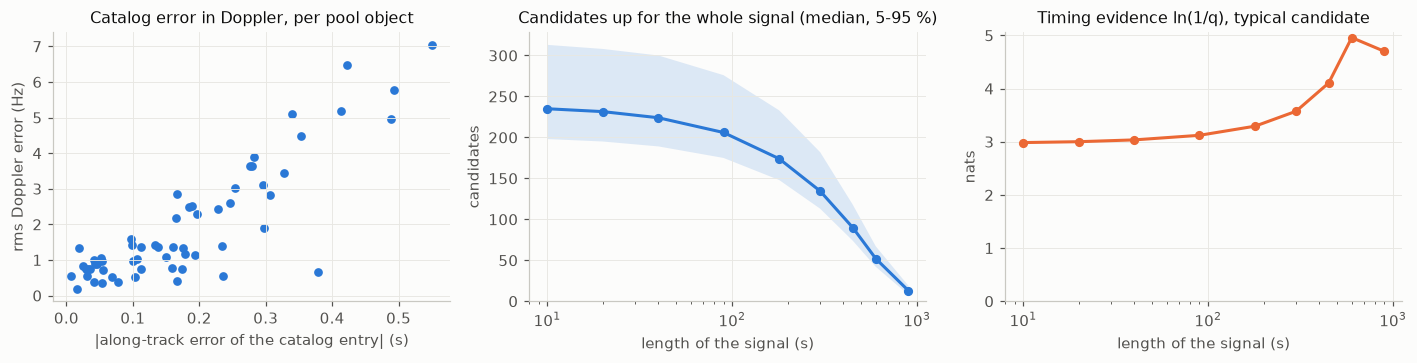

In [2]:
for stage, n in C.funnel:
    print(f"{n:6d}  {stage}")

# How well does the candidate predictor reproduce ASSIST's truth? The truth orbit of every pool object is perturbed
# (along-track sigma 0.25 s, RAAN sigma 0.01 deg), so this is the catalog error the scoring has to live with.
err = []
for n in C.pool:
    i = C.cat.index(n)
    tps = C.truth[n][:20]
    t_all = np.concatenate([tp.t for tp in tps]).astype(float)
    pred = L.doppler_single(C.cat.sats[i], C.station, t_all)
    d = pred - np.concatenate([tp.doppler for tp in tps])
    err.append((n, np.sqrt(np.mean(d**2)), np.abs(d).max(), C.perturb[n][0]))
err = np.array(err)
print(f"\npredicted minus true Doppler over {len(err)} pool objects: rms median {np.median(err[:, 1]):.2f} Hz, "
      f"90th percentile {np.percentile(err[:, 1], 90):.2f} Hz, worst peak {err[:, 2].max():.1f} Hz")

rng = np.random.default_rng(0)
lengths = [10, 20, 40, 90, 180, 300, 450, 600, 900]
starts = C.t0 + rng.uniform(0, 13 * 86400, 400)
n_vis = np.array([[len(np.unique(C.pt.cand[C.pt.containing(a, a + ln, 5.0)])) for a in starts] for ln in lengths])
q = np.array([np.median((v := C.pt.visible_fraction(max(ln - 10, 0)))[v > 0]) for ln in lengths])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].scatter(np.abs(err[:, 3]), err[:, 1], s=22, color=COL[0])
ax[0].set(xlabel="|along-track error of the catalog entry| (s)", ylabel="rms Doppler error (Hz)", title="Catalog error in Doppler, per pool object")
ax[1].plot(lengths, np.median(n_vis, axis=1), marker="o")
ax[1].fill_between(lengths, np.percentile(n_vis, 5, axis=1), np.percentile(n_vis, 95, axis=1), alpha=0.15, lw=0)
ax[1].set(xlabel="length of the signal (s)", ylabel="candidates", xscale="log", ylim=(0, None), title="Candidates up for the whole signal (median, 5-95 %)")
ax[2].plot(lengths, -np.log(q), marker="o", color=COL[1])
ax[2].set(xlabel="length of the signal (s)", ylabel="nats", xscale="log", ylim=(0, None), title="Timing evidence ln(1/q), typical candidate")
plt.tight_layout()

- **4321 candidates** remain of 16 987 catalogued objects; Starlink and OneWeb are 11 842 of those removed.
- The predictor reproduces ASSIST's truth to within the injected catalog error: about 13 Hz rms of Doppler error per
  second of along-track error, 1.3 Hz rms for the median pool object. A realistic element set therefore leaves a
  misfit of **a few Hz** on the true satellite, which is why the Doppler fit below does not treat misfits under 2 Hz
  as evidence and carries an along-track term.
- About **230 candidates** are up for the whole of a 20 s signal, about 50 for a 10 min one. Visibility alone
  never identifies anything from one signal; what it gives per session is about 3 nats (20 : 1) for a short signal
  and up to 5 nats for a long one.

## 2 · Campaign simulator

A campaign is two weeks. Rendering that as IQ is out of the question (17 GB/h), so the campaign is built from ASSIST's
**truth** and passed through an **emulator of detection + FFT tracking**:

- **Truth.** [scenarios/sco_campaign.yaml](scenarios/sco_campaign.yaml) puts a continuous carrier on 60 catalog objects
  (the five known zombies, four objects chosen because they fly in formation, 51 drawn at random). `assist truth`
  gives, per second of every pass, the true Doppler, elevation and C/N0. Every true orbit is perturbed against its
  catalog entry (along-track σ 0.25 s, RAAN σ 0.01°).
- **Transmitter behaviour**, injected at track level: keying or bursts, silent passes, switching off in the Earth's
  shadow, and the oscillator: a rest frequency that moves from pass to pass, linear and thermal-like in-pass drift, a
  random walk, sudden jumps (ALOUETTE-2), an offset at every turn-on, and the **turn-off droop** of `droop.png`
  (a fast exponential of about 350 Hz over the last seconds, plus a slower, smaller one).
- **Tracker**, with the numbers measured in `0_detection` and `1_tracking`: a detection needs 12–17 s of signal above
  12 dB-Hz; seconds are accepted with a probability that reaches 90 % at 13 dB-Hz; noise at the Cramér–Rao bound of a
  1 s block; a track ends after 30 s without a measurement or at a jump larger than the ±6 Hz search window, and then
  needs a new detection; a droop is followed until it is faster than 10–40 Hz/s.
- **Mismeasurements**: 2 % isolated bad bins (70 % inside the search window, 30 % gross, 20–300 Hz) and, about once per
  15 min of track, a run of ~6 bad seconds 0–40 Hz off and drifting (the tracker following something else).

What is stored per detection is what the real system would store: the 1 s bins (time, frequency), hence start, end and
centre frequency. The oscillator magnitudes are my assumptions (only the droop is taken from a real pass); the six
archetypes below are meant to span the behaviours described, not to reproduce particular satellites.

pool of 60 transmitters: 19 isolated, 29 in a train (another catalog object within 5 min on half of their passes),
12 with companions (another catalog object within 1 min on 80 % of their passes):
   TIANHUI 2-01A          with TIANHUI 2-01B
   PIESAT-1 B             with PIESAT-1 A, PIESAT-1 C
   ISS (ZARYA)            with ISS (UNITY), ISS (ZVEZDA), ISS (DESTINY) and 7 more
   TIANHUI 5C             with TIANHUI 5D
   YAOGAN-40 01C          with YAOGAN-40 01A, YAOGAN-40 01B
   YAOGAN-40 02B          with YAOGAN-40 02A, YAOGAN-40 02C
   KOWSAR 1.5             with FLOCK 4H-6
   SHARJAH-SAT-2          with IRIDE-MS1-EAGLET 2-10
   HAWK-5C                with HAWK-5B, HAWK-5A
   R5-S9                  with BALKAN-3
   TIANHUI 5B             with TIANHUI 5A
   NEONSAT-06             with 2026-229M

archetype zenith C/N0  schedule                       oscillator
beacon          40 dB-Hz  continuous                                                   pass-to-pass 5 Hz
zombie          33 dB-

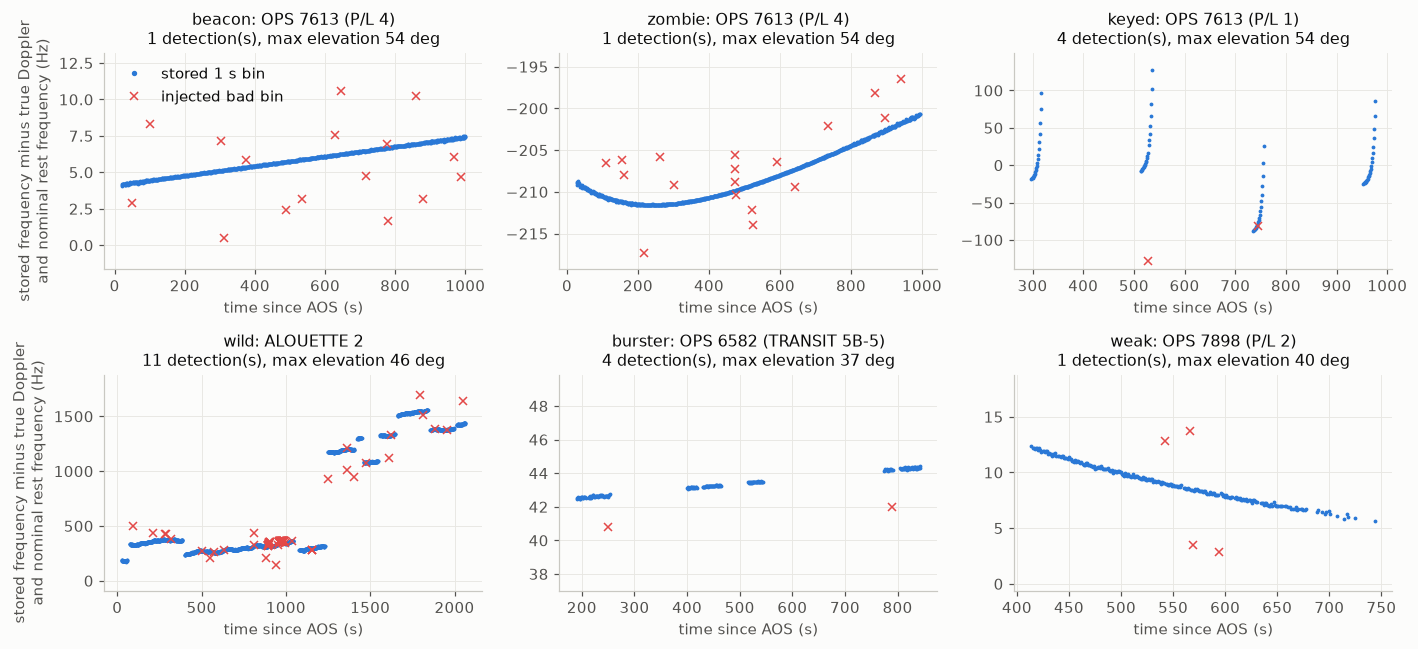

In [3]:
cnt = Counter(KIND.values())
print(f"pool of {len(C.pool)} transmitters: {cnt['isolated']} isolated, {cnt['train']} in a train (another catalog object within 5 min on half of their passes),")
print(f"{cnt['companions']} with companions (another catalog object within 1 min on 80 % of their passes):")
for n in C.pool:
    if C.companions[n]:
        print(f"   {C.name(n):22s} with {', '.join(C.name(m) for m in C.companions[n][:3])}" + (f" and {len(C.companions[n]) - 3} more" if len(C.companions[n]) > 3 else ""))
print(f"\n{'archetype':9s} {'zenith C/N0':>11s}  schedule                       oscillator")
for p in L.PROFILES.values():
    sched = "continuous" if not p.keying and not p.bursts else (f"keyed {p.keying[0]:.0f} s on / {p.keying[1]:.0f} s off" if p.keying else f"bursts {p.bursts[1]:.0f}-{p.bursts[2]:.0f} s, mean gap {p.bursts[0]:.0f} s")
    sched += (", sunlit only" if p.sunlit_only else "") + (f", on in {p.p_pass:.0%} of passes" if p.p_pass < 1 else "")
    o = p.osc
    osc = f"pass-to-pass {o.pass_sigma:.0f} Hz" + (f", thermal {o.thermal_amp:.0f} Hz" if o.thermal_amp else "") + (f", walk {o.walk} Hz/sqrt(s)" if o.walk else "")
    osc += (f", jump every ~{1 / o.jump_rate:.0f} s" if o.jump_rate else "") + (f", restart {o.restart_sigma:.0f} Hz" if o.restart_sigma else "") + (f", droop {o.droop_amp:.0f} Hz" if o.droop_amp else "")
    print(f"{p.name:9s} {p.cn0_zenith:8.0f} dB-Hz  {sched:60s} {osc}")


def example_pass(norad, profile, seed, min_el=35.0):
    """A high pass of this transmitter with plenty of stored bins: the true pass and its detections."""
    rng = np.random.default_rng(seed)
    best = (0, None, None)
    for tp in C.truth[norad][:60]:
        if tp.max_el < min_el:
            continue
        dets = L.emulate_pass(tp, L.PROFILES[profile], 136.75e6, rng, lit=C.lit(tp), droop_sign=1.0)
        n_bins = sum(len(d.t) for d in dets)
        if n_bins > best[0]:
            best = (n_bins, tp, dets)
        if n_bins > 150:
            break
    return best[1], best[2]


fig, ax = plt.subplots(2, 3, figsize=(13, 6), sharex=False)
for a, (norad, prof, seed) in zip(ax.ravel(), [(4237, "beacon", 1), (4237, "zombie", 3), (4256, "keyed", 3), (1804, "wild", 5), (965, "burster", 2), (5680, "weak", 4)], strict=True):
    tp, dets = example_pass(norad, prof, seed)
    for d in dets:
        true_dop = np.interp(d.t, tp.t, tp.doppler) * (136.75e6 / L.F0)
        resid = d.f - 136.75e6 - true_dop
        a.plot(d.t[~d.bad] - tp.t[0], resid[~d.bad], ".", ms=3, color=COL[0])
        a.plot(d.t[d.bad] - tp.t[0], resid[d.bad], "x", ms=5, color=COL[7])
    r_all = np.concatenate([d.f - 136.75e6 - np.interp(d.t, tp.t, tp.doppler) * (136.75e6 / L.F0) for d in dets])
    lo, hi = np.percentile(r_all, [2, 98])
    a.set(ylim=(lo - 0.25 * (hi - lo) - 5, hi + 0.25 * (hi - lo) + 5), title=f"{prof}: {C.name(norad)}\n{len(dets)} detection(s), max elevation {tp.max_el:.0f} deg")
    a.set_xlabel("time since AOS (s)")
ax[0, 0].set_ylabel("stored frequency minus true Doppler\nand nominal rest frequency (Hz)")
ax[1, 0].set_ylabel("stored frequency minus true Doppler\nand nominal rest frequency (Hz)")
ax[0, 0].plot([], [], ".", color=COL[0], label="stored 1 s bin")
ax[0, 0].plot([], [], "x", color=COL[7], label="injected bad bin")
ax[0, 0].legend(loc="best")
plt.tight_layout()

Each panel is one pass with the true Doppler and the nominal rest frequency removed, i.e. what the transmitter and the
tracker add: the thermal curve of the `zombie`, the droop at the end of each on-period of the `keyed` one, the jumps
and wander of the `wild` one (every jump ends a detection), and the injected bad bins.

One property of the pool matters for everything that follows and is a finding in itself: **of the 51 objects drawn
at random, only 14 fly alone**; 29 fly in a train and 8 have companions within a minute. A random draw from today's
catalog (after removing Starlink and OneWeb) is mostly constellation members and rideshare batches. The five known
zombies are all isolated.

## 3 · Fine pipeline: Doppler evidence of one session

**Session.** A keyed transmitter gives several detections per pass. They share one pass geometry, so they are one
observation: detections on a channel less than 400 s apart form a **session**, and all evidence is per session.
Tracks are thinned to at most 300 bins.

**Model of a session under candidate H.** With $D_H(t)$ the predicted Doppler curve and $k$ the detection a bin
belongs to,

$$ f_\text{obs}(t) = D_H(t) + \Delta\!t\,\dot D_H(t) + c + \delta_k + d\,(t-\bar t) + \textstyle\sum_j b_j \cos\frac{j\pi (t-t_0)}{T} + a_k\,e^{-(t_{\text{end},k}-t)/5\,\text{s}} + a'_k\,e^{-(t_{\text{end},k}-t)/20\,\text{s}} + \varepsilon(t) $$

| Term | Stands for | Prior (σ) |
|---|---|---|
| $\Delta t\,\dot D_H$ | along-track (timing) error of the element set | 0.5 s |
| $c$ | rest frequency of this pass; recorded as the implied rest frequency $c_H$ | free |
| $\delta_k$ | a step at each new detection (turn-on offset, or a jump that broke the track) | 150 Hz |
| $d$ | linear drift | 0.3 Hz/s |
| $b_j$ | smooth wander (thermal), one cosine term per 120 s of session, at most 8 | 20 Hz each |
| $a_k, a'_k$ | turn-off droop at the end of each detection, a fast and a slow tail | 300 Hz, 60 Hz |

All of these are linear, so they are solved inside the fit; the priors keep them from imitating an orbit.

**Robust loss.** $\varepsilon$ is Student-t with ν = 3. Its scale σ is fitted per candidate but never below
**2 Hz**: misfits smaller than what element-set error produces anyway are not evidence. The fit is iteratively
reweighted least squares from two starts (per-detection medians, with and without a robust slope), because the loss
is not convex.

**What the candidate is compared with.** "The signal is a satellite, but not H" is represented twice:

- K = 500 **decoys**: Doppler curves of random catalog passes laid over the session so that the satellite is up
  throughout, the same condition real candidates meet, fitted with the same transmitter model. A free cubic (the
  "smooth curve no orbit explains" of the brief, with a BIC penalty) is added to them as one more decoy.
- a **free orbit**: six orbital parameters fitted to the track (two-body, started from the best candidates and
  decoys), with the same transmitter model. It answers "could *some* orbit explain this track much better than H
  does?", which decoys cannot, because no decoy is ever close to the true orbit of a long track.

**Doppler evidence.** With $p_H$ the maximised likelihood of H, $p_1 \dots p_K$ those of the decoys and $p_\text{orb}$
that of the free orbit,

$$ \ell(H) = \frac{p_H}{\max\!\left[\ \tfrac{1}{K+1}\big(p_H + \textstyle\sum_k p_k\big),\ \ e^{-6.2}\,p_\text{orb}\ \right]} \ \le\ K+1 $$

Three properties matter:

- *Honest for bystanders.* A candidate that has nothing to do with the signal is one more curve like the decoys, so
  against the first term $E[\ell] = 1$ whatever the oscillator or the tracker did; the second term can only lower it.
- *Bounded.* One session never claims more than about 500 : 1.
- *Absolute, not only relative.* A neighbour of an uncatalogued transmitter fits better than every decoy, but far
  worse than the free orbit, and gets ℓ ≪ 1. The factor $e^{-6.2}$ = 1/500 is the most a catalog orbit is preferred
  over an equally good free one.

When a track is too short to tell orbits apart, most decoys fit as well as H and $\ell \approx 1$ by itself.

**Effective sample size.** Log-likelihoods are multiplied by $n_\text{eff}/n$, with $n_\text{eff}$ from the lag-1
autocorrelation of the best model's residuals, so that a wandering oscillator (correlated residuals) does not count
as hundreds of independent bins.

**Not a satellite.** The same transmitter model with no Doppler at all and a drift of at most 0.05 Hz/s gives the
likelihood of "a spur or ground carrier". Sessions shorter than 120 s cannot support it (a short burst from a slow,
high satellite is flat too).

### 3.1 Loss functions under bad bins

The simplest setting first, the one of the brief: a clean 90 s track, offset-only fit, a growing share of bins replaced
by errors of 20–300 Hz, and the question "is the true satellite ranked first?". All ~220 catalog objects visible
during the track are candidates.

bad bins    windows  candidates   misidentified: least squares   Student-t   clipped chi2
     0%        800         220                        0.1%        0.1%           0.1%
     3%        800         222                       33.9%        0.0%           0.0%
    10%        800         223                       57.6%        0.4%           0.4%
    20%        800         220                       67.2%        0.1%           0.1%
    30%        800         220                       73.2%        0.0%           0.0%
    40%        800         221                       76.4%        0.1%           0.1%
    50%        800         223                       81.0%        0.0%           0.0%


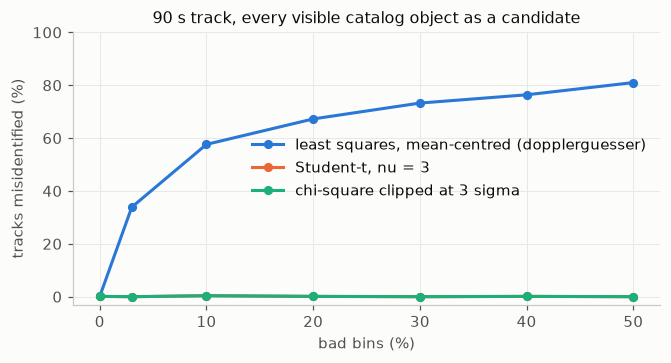

In [4]:
BAD = [0, 0.03, 0.1, 0.2, 0.3, 0.4, 0.5]
A = cached("expA", lambda: L.run_pool(L.mc_simple, [dict(seed=1000 * i + j, norad=n, window_s=90, bad=b, n=20) for j, b in enumerate(BAD) for i, n in enumerate(ISOLATED[:40])]))
tab = {}
for j, b in enumerate(BAD):
    recs = [r for k in range(40) for r in A[j * 40 + k]]
    tab[b] = {loss: 1 - np.mean([r[loss] for r in recs]) for loss in ("ls", "t", "clip")} | {"n": len(recs), "cand": np.mean([r["n_cand"] for r in recs])}
print("bad bins    windows  candidates   misidentified: least squares   Student-t   clipped chi2")
for b, r in tab.items():
    print(f"{b:7.0%} {r['n']:10d} {r['cand']:11.0f} {r['ls']:27.1%} {r['t']:11.1%} {r['clip']:14.1%}")

fig, ax = plt.subplots(figsize=(6.2, 3.4))
for loss, lab in (("ls", "least squares, mean-centred (dopplerguesser)"), ("t", "Student-t, nu = 3"), ("clip", "chi-square clipped at 3 sigma")):
    ax.plot([100 * b for b in BAD], [100 * tab[b][loss] for b in BAD], marker="o", label=lab)
ax.set(xlabel="bad bins (%)", ylabel="tracks misidentified (%)", ylim=(-3, 100), title="90 s track, every visible catalog object as a candidate")
ax.legend()
plt.tight_layout()

- Without bad bins all three losses agree (1 track in 800 misidentified).
- **Least squares fails as soon as bins go bad: 34 % of tracks misidentified at 3 % bad bins, 58 % at 10 %.** That is
  worse than the 16 % / 42 % of the brief's simulation, because here the true satellite competes with ~220 real
  candidates instead of 6.
- **Student-t and clipped χ² stay at or below 0.4 % up to 50 % bad bins**, and are indistinguishable from each other.
  Student-t is used from here on because its scale can be fitted, which the unstable oscillators below need.

### 3.2 How long must a track be?

Clean transmitter (`beacon`), default fit and default mismeasurements; one window of the given length is cut from
every pass.

track   tracks  true not ranked 1st   ln l(true): 10 % / median / 90 %   mean l of wrong candidates   decoys that fit
  10 s     600              33.3%               0.9 /  1.1 /  2.2                   1.02                 218 of 500
  20 s     600              19.8%               1.4 /  1.8 /  3.8                   1.00                 128 of 500
  30 s     600               8.8%               2.1 /  2.8 /  5.2                   0.97                  52 of 500
  45 s     600               8.0%               2.6 /  3.5 /  5.5                   0.91                  26 of 500
  60 s     600               4.3%               3.1 /  4.3 /  5.5                   0.86                  11 of 500
  90 s     600               1.5%               4.2 /  5.5 /  5.5                   0.63                   3 of 500
 180 s     600               0.3%               5.3 /  5.5 /  5.6                   0.25                   1 of 500
 400 s     600               0.0%               5.4 /  5.5 /  5.6     

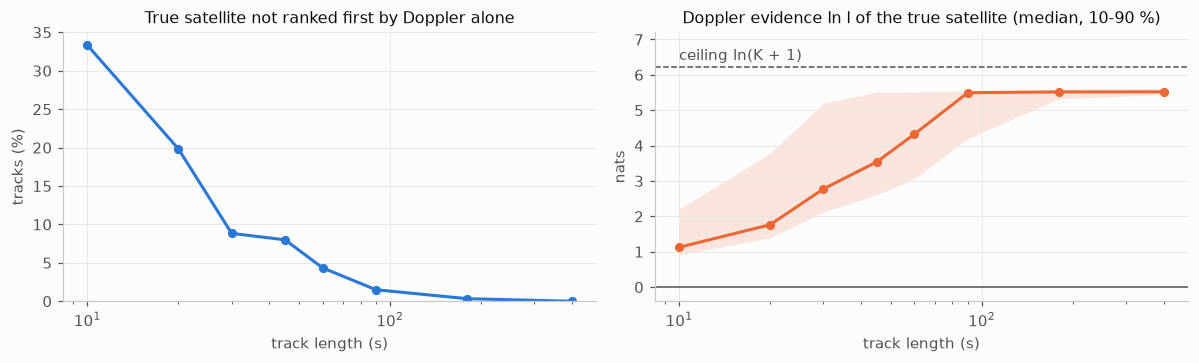

In [5]:
WINDOWS = [10, 20, 30, 45, 60, 90, 180, 400]
B = cached("expB", lambda: L.run_pool(L.mc_fine, [dict(seed=5000 + 100 * i + j, norad=n, profile="beacon", window_s=w, cfgs={"default": {}}, max_sessions=20) for j, w in enumerate(WINDOWS) for i, n in enumerate(ISOLATED[:30])]))
rows = []
for j, w in enumerate(WINDOWS):
    recs = [r for k in range(30) for r in B[j * 30 + k]["default"] if r["in"]]
    le = np.array([r["log_ell"] for r in recs])
    rk = np.array([r["rank_dop"] for r in recs])
    rows.append((w, len(recs), np.mean(rk > 1), np.percentile(le, [10, 50, 90]), np.nanmean([r["mean_ell_wrong"] for r in recs]), np.median([r["dec_eff"] for r in recs])))
print("track   tracks  true not ranked 1st   ln l(true): 10 % / median / 90 %   mean l of wrong candidates   decoys that fit")
for w, n, mis, pc, mw, de in rows:
    print(f"{w:4d} s {n:7d} {mis:18.1%} {pc[0]:17.1f} / {pc[1]:4.1f} / {pc[2]:4.1f} {mw:22.2f} {de:19.0f} of {L.FitConfig().n_decoys}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(WINDOWS, [100 * r[2] for r in rows], marker="o")
ax[0].set(xscale="log", xlabel="track length (s)", ylabel="tracks (%)", ylim=(0, None), title="True satellite not ranked first by Doppler alone")
ax[1].plot(WINDOWS, [r[3][1] for r in rows], marker="o", color=COL[1])
ax[1].fill_between(WINDOWS, [r[3][0] for r in rows], [r[3][2] for r in rows], color=COL[1], alpha=0.15, lw=0)
ax[1].axhline(np.log(L.FitConfig().n_decoys + 1), color=MUTED, lw=1, ls="--")
ax[1].text(WINDOWS[0], np.log(L.FitConfig().n_decoys + 1) + 0.1, "ceiling ln(K + 1)", va="bottom", color=MUTED)
ax[1].axhline(0, color=MUTED, lw=1)
ax[1].set(xscale="log", xlabel="track length (s)", ylabel="nats", ylim=(-0.4, 7.2), title="Doppler evidence ln l of the true satellite (median, 10-90 %)")
plt.tight_layout()

- **Short tracks cannot decide.** The true satellite is not ranked first in 33 % of 10 s tracks and 20 % of 20 s
  tracks (the brief's simulation: about 20 % at 20 s), 9 % at 30 s, 1.5 % at 90 s, none at 400 s.
- The evidence says so by itself: for a 10 s track over 200 of the 500 decoys fit as well as the true satellite and
  its ℓ is about 3; from 90 s on at most a few decoys fit and ℓ sits at its working ceiling of about 250
  (the 1/500 handicap of the free orbit keeps it just under K + 1).
- For wrong candidates ℓ averages 1 or less at every length, as designed. A short burst therefore contributes its
  timing evidence and little else, without any special rule for bursts.

### 3.3 Oscillator behaviour against the transmitter model

Each archetype is scored with increasingly complete transmitter models; 16 sessions of 24 transmitters each.

In [6]:
OFF = dict(drift_order=0, sigma_seg=0.0, droop_tau=(), wander_s=0.0, sigma_along=0.0, free_orbit=False)
CFGS = {
    "LS, offset only (dopplerguesser)": OFF | dict(loss="ls", n_eff=False),
    "t, offset only": OFF,
    "t + drift": OFF | dict(drift_order=1),
    "t + drift + steps": OFF | dict(drift_order=1, sigma_seg=150.0),
    "... + droop tails": OFF | dict(drift_order=1, sigma_seg=150.0, droop_tau=(5.0, 20.0)),
    "... + wander + along-track": dict(free_orbit=False),
    "... + free-orbit reference (default)": dict(),
    "default without n_eff scaling": dict(n_eff=False),
}
DEFAULT = "... + free-orbit reference (default)"
ARCH = ["beacon", "zombie", "keyed", "wild", "burster", "weak"]
Cx = cached("expC", lambda: L.run_pool(L.mc_fine, [dict(seed=7000 + 100 * i + j, norad=n, profile=p, cfgs=CFGS, max_sessions=16) for j, p in enumerate(ARCH) for i, n in enumerate(ISOLATED[:24])]))
res = {}
for j, p in enumerate(ARCH):
    for cf in CFGS:
        recs = [r for k in range(24) for r in Cx[j * 24 + k][cf] if r["in"]]
        le = np.array([r["log_ell"] for r in recs])
        res[p, cf] = dict(n=len(recs), top1=np.mean([r["rank_dop"] == 1 for r in recs]), med=np.median(le), rej=np.mean(le < -3),
                          wrong=np.nanmean([r["mean_ell_wrong"] for r in recs]), sigma=np.median([r["sigma"] for r in recs]), neff=np.median([r["n_eff"] for r in recs]))  # fmt: skip
for title, key, fmt in (("True satellite ranked first by Doppler alone", "top1", "{:8.0%}"), ("Median Doppler evidence ln l of the true satellite (nats; ceiling 6.2, about 5.5 once the free orbit is in)", "med", "{:8.1f}"),
                        ("True satellite rejected by Doppler (ln l < -3)", "rej", "{:8.1%}"), ("Mean l of wrong candidates (calibrated: about 1 or less)", "wrong", "{:8.2f}")):  # fmt: skip
    print(f"\n{title}\n{'':38s}" + "".join(f"{p:>8s}" for p in ARCH))
    for cf in CFGS:
        print(f"{cf:38s}" + "".join(fmt.format(res[p, cf][key]) for p in ARCH))
print("\nsessions per archetype:", {p: res[p, "t, offset only"]["n"] for p in ARCH})
print("default fit, median residual scale (Hz):", {p: round(float(res[p, DEFAULT]["sigma"]), 1) for p in ARCH})
print("default fit, median effective bins:    ", {p: round(float(res[p, DEFAULT]["neff"])) for p in ARCH})


True satellite ranked first by Doppler alone
                                        beacon  zombie   keyed    wild burster    weak
LS, offset only (dopplerguesser)          100%     89%     62%     44%     89%     96%
t, offset only                            100%     90%     62%     44%     94%     97%
t + drift                                 100%     90%     51%     49%     96%     98%
t + drift + steps                         100%     90%     34%     83%     96%     98%
... + droop tails                         100%     94%     66%     81%     92%     99%
... + wander + along-track                100%     92%     66%     73%     92%     99%
... + free-orbit reference (default)      100%     92%     66%     73%     92%     99%
default without n_eff scaling             100%     92%     66%     73%     92%     99%

Median Doppler evidence ln l of the true satellite (nats; ceiling 6.2, about 5.5 once the free orbit is in)
                                        beacon  zombie   keyed

- **dopplerguesser's scoring breaks on unstable oscillators.** For the ALOUETTE-like `wild` transmitter the true
  satellite is rejected outright in 83 % of sessions (median ln ℓ = −89) and ranked first in 44 %, which matches the
  confident misidentifications seen in practice. For the keyed zombie it is rejected in 64 % of sessions.
- A robust loss alone removes most rejections but not the confusion (`wild` still 44 % first).
- **Steps between detections** are what an oscillator that jumps needs (`wild`: 49 % → 83 % first): the tracker loses
  a jumping carrier and re-detects it, so every jump is a new detection and gets its own offset.
- **The droop tails** are what a keyed zombie needs (34 % → 66 % first, rejections 19 % → 0 %). Without them the
  end of every 25 s on-period is misfit, and the freedom of drift and steps is spent on following the droop, which is
  why adding those first makes things worse.
- **Wander and along-track terms** halve the remaining rejections of the thermally drifting `zombie`
  (4 % → 2 %) and cost the `wild` transmitter some sharpness (81 % → 73 % first). They are kept because of
  what comes next.
- **The free-orbit reference** changes little for true satellites (it caps ℓ at about 250 and rejects 5 % of
  `zombie` and `wild` sessions) but is what makes the evidence absolute: the mean ℓ of wrong candidates drops to
  0.06–0.2 on long tracks. Its effect is measured at campaign level in section 6.
- **Effective-sample-size scaling** keeps a wandering oscillator from rejecting its own satellite
  (`wild`: 35 % rejected without it, 5 % with it).
- With the default model the true satellite is ranked first by Doppler alone in 66 % (keyed) to 100 % (beacon) of
  sessions. A rejected session costs the campaign score almost nothing (section 5), so the 5 % are tolerable.

### 3.4 Is the evidence honest when the true satellite is not a candidate?

The same sessions, with the true transmitter removed from the catalog. Every remaining candidate is now "unrelated",
so its ℓ should average about 1, and a candidate should reach the ceiling only as often as chance among K decoys
allows.

In [7]:
Cn = cached("expC_absent", lambda: L.run_pool(L.mc_fine, [dict(seed=8000 + 100 * i + j, norad=n, profile=p, cfgs={"default": {}}, max_sessions=16, exclude_truth=True) for j, p in enumerate(ARCH) for i, n in enumerate(ISOLATED[:24])]))
print(f"{'archetype':9s} sessions  candidates  mean l over all candidates   sessions where some candidate has ln l >= 5   expected from K = 500 decoys")
for j, p in enumerate(ARCH):
    recs = [r for k in range(24) for r in Cn[j * 24 + k]["default"] if r["n_cand"]]
    nc = np.mean([r["n_cand"] for r in recs])
    print(f"{p:9s} {len(recs):8d} {nc:11.0f} {np.mean([r['mean_ell_wrong'] for r in recs]):18.2f} {np.mean([r['max_ell_wrong'] >= 5 for r in recs]):34.0%} {nc / (nc + 500):37.0%}")

archetype sessions  candidates  mean l over all candidates   sessions where some candidate has ln l >= 5   expected from K = 500 decoys
beacon         380          56               0.11                                 3%                                   10%
zombie         378          90               0.13                                 2%                                   15%
keyed          377         136               0.92                                 4%                                   21%
wild           377         100               0.72                                 5%                                   17%
burster        384         182               0.86                                 4%                                   27%
weak           320         164               0.11                                 3%                                   25%


The mean ℓ over all candidates is 0.1–0.9 for every oscillator behaviour, and a candidate reaches ln ℓ ≥ 5 in
2–5 % of sessions, several times less often than exchangeability with the decoys alone would allow. The Doppler
evidence does not manufacture support for bystanders.

### 3.5 Element-set error

The true orbits already differ from the catalog (along-track σ 0.25 s). Here every track is additionally shifted in
time, which is what a stale element set does (the satellite runs late or early against its prediction).

In [8]:
SHIFTS = [0, 0.5, 1, 2, 4, 8]
D = cached("expD", lambda: L.run_pool(L.mc_fine, [dict(seed=9000 + 100 * i + 10 * j + k, norad=n, profile=p, cfgs={"default": {}}, max_sessions=12, t_shift=sh) for k, p in enumerate(("beacon", "keyed")) for j, sh in enumerate(SHIFTS) for i, n in enumerate(ISOLATED[:20])]))
print("extra along-track error    beacon: ranked 1st   median ln l   rejected      keyed: ranked 1st   median ln l   rejected")
for j, sh in enumerate(SHIFTS):
    line = f"{sh:16.1f} s     "
    for k in range(2):
        recs = [r for i in range(20) for r in D[k * len(SHIFTS) * 20 + j * 20 + i]["default"] if r["in"]]
        le = np.array([r["log_ell"] for r in recs])
        line += f"{np.mean([r['rank_dop'] == 1 for r in recs]):18.0%} {np.median(le):13.1f} {np.mean(le < -3):10.0%}      "
    print(line)

extra along-track error    beacon: ranked 1st   median ln l   rejected      keyed: ranked 1st   median ln l   rejected
             0.0 s                   100%           5.5         0%                     62%           3.5         0%      
             0.5 s                    99%           5.5         0%                     65%           3.7         0%      
             1.0 s                   100%           5.4         0%                     67%           3.8         0%      
             2.0 s                    98%           4.9         5%                     65%           3.6         0%      
             4.0 s                    95%           3.4        30%                     60%           3.6         0%      
             8.0 s                    87%          -7.5        56%                     54%           3.5         0%      


- Up to 1 s of extra along-track error (8 km) costs nothing; the along-track term absorbs it.
- At 2 s the true satellite is rejected in 5 % of long clean passes, at 4 s in 30 %, at 8 s in more than half.
  The free-orbit reference is what makes this sharp: a track that a slightly different orbit explains much better is
  evidence against the catalog entry, whether the entry is wrong or merely stale.
- Short keyed tracks do not notice: they cannot resolve seconds of along-track error (nor a neighbour that close).
- Element sets must therefore be within a second or two of the truth, which is what the nearest-epoch rule is for.
  An object with stale elements keeps its timing and short-track evidence and loses its long passes.

## 4 · Coarse pipeline: timing evidence of one session

A candidate that was not up for the whole session cannot have sent it. One that was up gets credit, and the credit is
larger the less often that happens by chance:

$$ \tau(H) = \frac{1}{q_H(L)}, \qquad q_H(L) = \frac{\sum_{\text{passes } p \text{ of } H} \max(0,\ \text{duration}_p - L)}{\text{campaign time}} $$

$q_H(L)$ is the fraction of time at which a signal of length $L$ would fit inside a pass of H. It is the probability
that an unrelated signal is "explained" by H, so $\tau$ is a likelihood ratio against an unrelated source, and again
$E[\tau] = 1$ for a candidate that has nothing to do with the signal. Objects that are overhead often (high orbits,
high-inclination orbits seen from 55° N) have a large $q$ and get little credit per session: that is the correction
for "often visible" the coarse pipeline needs.

Only sessions enter. A pass of H during which nothing was heard is never looked at, so silence costs nothing.

zombie   sessions until the true satellite is the only one visible in all of them: median 3, 90th percentile 6; not within 12 sessions: 3%
keyed    sessions until the true satellite is the only one visible in all of them: median 4, 90th percentile 8; not within 12 sessions: 13%
burster  sessions until the true satellite is the only one visible in all of them: median 5, 90th percentile 7; not within 12 sessions: 13%
visible fraction q over the catalog: median 0.051, 5-95 % 0.028-0.097, largest 0.29; 48 objects never rise at this station


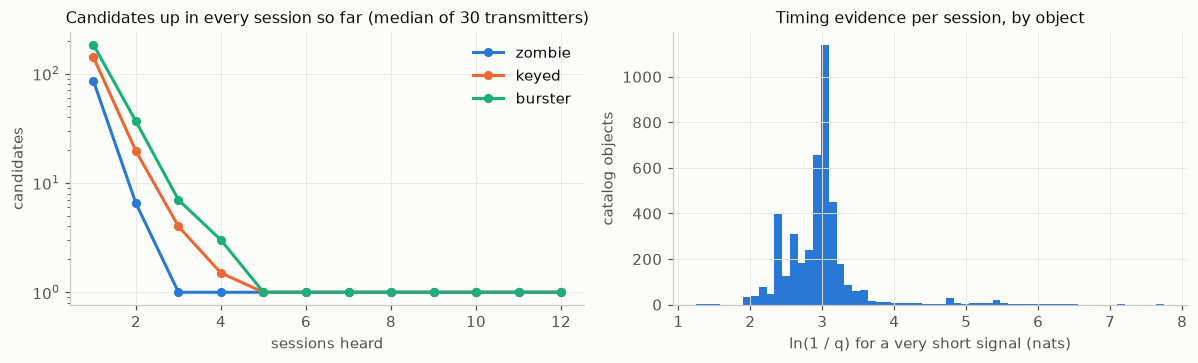

In [9]:
def timing_survivors(norad, profile, seed, n_max=12):
    """Candidates that were visible in every one of the first n sessions of a transmitter (timing only)."""
    rng = np.random.default_rng(seed)
    sessions = L.make_sessions(C.emulate(norad, profile, 136.75e6, rng))
    alive, out, taus = None, [], []
    ti = C.cat.index(norad)
    for s in sessions[:n_max]:
        cand = np.unique(C.pt.cand[C.pt.containing(s.t0, s.t1, 5.0)])
        alive = set(cand) if alive is None else alive & set(cand)
        out.append(len(alive))
        taus.append(-np.log(C.pt.visible_fraction(max(s.span - 10, 0))[ti]))
    return out + [np.nan] * (n_max - len(out)), taus


surv = {p: np.array([timing_survivors(n, p, 40 + i)[0] for i, n in enumerate(ISOLATED[:30])]) for p in ("zombie", "keyed", "burster")}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for p, sv in surv.items():
    ax[0].plot(np.arange(1, 13), np.nanmedian(sv, axis=0), marker="o", label=p)
ax[0].set(yscale="log", xlabel="sessions heard", ylabel="candidates", title="Candidates up in every session so far (median of 30 transmitters)")
ax[0].legend()
qall = C.pt.visible_fraction(0.0)
never = int(np.sum(qall == 0))
qall = qall[qall > 0]
ax[1].hist(-np.log(qall), bins=60, color=COL[0])
ax[1].set(xlabel="ln(1 / q) for a very short signal (nats)", ylabel="catalog objects", title="Timing evidence per session, by object")
plt.tight_layout()
for p, sv in surv.items():
    alone = np.array([next((k + 1 for k, v in enumerate(row) if v <= 1), np.nan) for row in sv])
    print(f"{p:8s} sessions until the true satellite is the only one visible in all of them: median {np.nanmedian(alone):.0f}, "
          f"90th percentile {np.nanpercentile(alone, 90):.0f}; not within 12 sessions: {np.mean(np.isnan(alone)):.0%}")
print(f"visible fraction q over the catalog: median {np.median(qall):.3f}, 5-95 % {np.percentile(qall, 5):.3f}-{np.percentile(qall, 95):.3f}, "
      f"largest {qall.max():.2f}; {never} objects never rise at this station")

- A typical object is up 5 % of the time at this station (2.8–9.7 % for nine in ten), so each session is worth about
  3 nats of timing evidence for a typical candidate, less for the ones that are overhead often (up to 29 % of the
  time).
- Hard elimination by visibility would isolate the true satellite after a median of 3–5 sessions, but for 13 % of
  the keyed and burst transmitters another object is still visible in every one of the first 12 sessions. These are
  the trains and companions of section 2. Timing alone therefore cannot be the decision, and hard elimination would
  also break as soon as two transmitters share a channel; the fusion below uses the same information as a likelihood.

## 5 · Fusion: one score per candidate per channel

**Channels.** Detections are grouped by centre frequency; a gap larger than the maximum LEO Doppler at 137 MHz
(3.6 kHz) plus 0.5 kHz of drift starts a new channel. A channel is "everything heard on roughly this frequency" and may
hold several transmitters. It is re-formed whenever detections are added.

**Evidence of one session.** For session $s$ and candidate H, timing and Doppler multiply:
$w_s(H) = \tau_s(H)\,\ell_s(H)$. Both factors have mean at most 1 for an unrelated candidate, so $E[w] \le 1$.

**A channel as a mixture of transmitters.** Each session was sent by *one* of: an unknown satellite (weight 1 by
construction), a non-satellite (weight = the no-Doppler likelihood ratio of section 3), or a catalog object
(weight $w_s(H)$). The channel is described by the shares $\pi$ of these sources,
$m_s = \pi_\text{unk} + \pi_\text{ns}\,w_s^\text{ns} + \sum_H \pi_H\,w_s(H)$. Catalog objects are added greedily while each
adds at least 3 nats, and the shares are fitted by EM.

**Campaign score.** For candidate H, build the best mixture **without** H, $m_s^{(-H)}$, and ask how much H improves
on it:

$$ \Lambda_H = \ln\ \underset{\varepsilon}{\text{mean}}\ \prod_s \left[\,1-\varepsilon+\varepsilon\,\min\!\Big(\frac{w_s(H)}{m_s^{(-H)}},\ e^{8}\Big)\right] \quad\text{(nats)} $$

$\varepsilon$ is the share of the channel's sessions that H accounts for; it is averaged over a grid from 2 % to 98 %.
Reading the product term by term:

- a session H explains well multiplies the odds by about $\varepsilon\,w/m$, but never by more than $e^8 \approx 3000$,
  however clean the track;
- a session H cannot explain (below the horizon, or the Doppler contradicts it) multiplies them by $1-\varepsilon$: a
  small fixed cost, never a veto, because another transmitter may share the channel;
- a pass of H without a session does not appear at all: **silence costs nothing**;
- a rival that explains the same sessions equally well sits in $m^{(-H)}$ and cancels H's evidence. Two objects flying
  together therefore both score near zero, and are reported as a group (section 6).

identified after sessions: {'fused': 5, 'timing': 16, 'doppler': 5} | sessions in 14 days: 95 from 390 detections


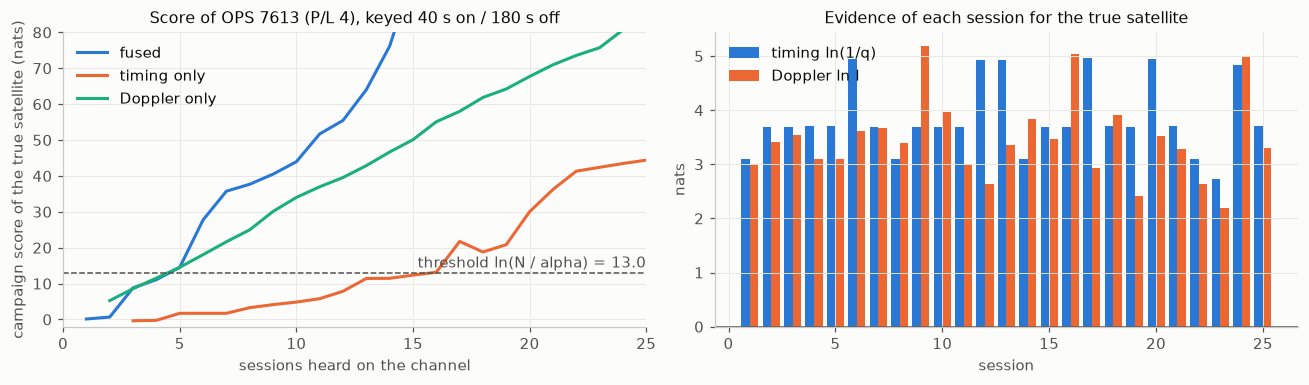

In [10]:
# One channel, session by session: a keyed zombie (OPS 7613 P/L 4) on its own frequency.
demo1 = cached("demo_keyed", lambda: L.mc_channel(dict(seed=11, txs=[(4237, "keyed", 136.7524e6)], modes=("fused", "timing", "doppler"))))
thr = L.DecisionConfig(n_candidates=len(C.cat)).threshold
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k, (mode, lab) in enumerate((("fused", "fused"), ("timing", "timing only"), ("doppler", "Doppler only"))):
    tr = demo1[mode]
    ax[0].plot(tr["steps"], [s[0] for s in tr["true_score"]], color=COL[k], label=lab)
ax[0].axhline(thr, color=MUTED, lw=1, ls="--")
ax[0].text(25, thr + 1.5, f"threshold ln(N / alpha) = {thr:.1f}", color=MUTED, ha="right")
ax[0].set(xlim=(0, 25), ylim=(-2, 80), xlabel="sessions heard on the channel", ylabel="campaign score of the true satellite (nats)", title="Score of OPS 7613 (P/L 4), keyed 40 s on / 180 s off")
ax[0].legend()
ss = demo1["sessions"]
ax[1].bar(np.arange(1, 26) - 0.2, [s.get("log_tau", 0) for s in ss[:25]], width=0.4, label="timing ln(1/q)")
ax[1].bar(np.arange(1, 26) + 0.2, [s.get("log_ell", 0) for s in ss[:25]], width=0.4, label="Doppler ln l")
ax[1].axhline(0, color=MUTED, lw=1)
ax[1].set(xlabel="session", ylabel="nats", title="Evidence of each session for the true satellite")
ax[1].legend()
plt.tight_layout()
first = {m: next((s for s, v in zip(demo1[m]["steps"], demo1[m]["verdicts"], strict=True) if any(x[0] == "identified" and x[1] == (4237,) for x in v)), None) for m in ("fused", "timing", "doppler")}
print("identified after sessions:", first, "| sessions in 14 days:", demo1["n_sessions"], "from", demo1["n_dets"], "detections")

On this channel each session gives the true satellite 3–5 nats of timing evidence and 2–5 nats of Doppler evidence
(four 25 s fragments per pass, each with its own offset and droop). Fused, the satellite is identified at session 5;
with timing alone at session 16, because other objects of similar orbits share many of the sessions.

## 6 · Decision rule

After every new session on a channel the scores are recomputed and the verdicts below are checked. A verdict, once
reached, stands.

**identified: H** requires all four:

1. **Score.** $\Lambda_H \ge \Lambda^* = \ln(N/\alpha)$ = 13.0 nats for N = 4321 candidates and α = 1 %.
2. **Support.** At least 3 sessions in which H is the most likely source (responsibility ≥ 0.5).
3. **Doppler confirmation.** The Doppler evidence alone, combined over the sessions like the score, reaches 8 nats,
   and at least 3 sessions individually have $\ell \ge 20$. Timing coincidence shows that the transmitter flies in
   H's part of the sky at H's times; only Doppler can show it is H and not another object of the same plane.
4. **Not merely kin.** Among the sessions that no catalog object explains, count those heard while H was *nearly* up
   (a pass within 10 min) but could not contain them. A second, unrelated transmitter on the channel puts only a
   share $p_H$ (typically 0.2–0.4) of its sessions there; a neighbour of H puts nearly all of them there. The
   log-likelihood ratio of the two readings is added to $\Lambda_H$ when it is negative. Note what this is not: it
   never looks at passes of H without a signal.

| Other verdict | Condition |
|---|---|
| **ambiguous: group G** | H has 3 supporting sessions but $\Lambda_H < \Lambda^*$ because rivals explain the same sessions; rivals are added to G (at most 12) until the group as a whole passes tests 1 and 3 |
| **related: H** | $\Lambda_H \ge \Lambda^*$ but the kin test puts the odds below 1 : 100: the transmitter is a neighbour of H, not H |
| **not a satellite** | the non-satellite source passes tests 1 and 2 |
| **satellite, not in catalog** | at least 5 sessions that are Doppler-shaped, informative (fewer than 25 of the 500 decoys fit) and attributed to the unknown satellite with responsibility ≥ 0.9, and they are at least a third of the channel's informative sessions |
| undecided | otherwise: keep listening |

**Why $\ln(N/\alpha)$.** If H has nothing to do with the channel, every factor of the product in $\Lambda_H$ has
expectation at most 1, so $e^{\Lambda_H}$ is a non-negative supermartingale (exactly so if the rival mixture were
fixed in advance; here it is refitted, which the Monte-Carlo below checks). By Ville's inequality the probability
that it *ever* exceeds $N/\alpha$, at any time during a campaign of any length, is at most $\alpha/N$. Summed over the
N candidates, the chance of a false identification on a channel is at most α. This is what makes the rule
sequential: the scores can be looked at after every session without inflating the error.

**Why tests 2–4 on top.** The bound covers bystanders. It does not cover objects that fly with, or near, the real
transmitter, whose visibility is anything but independent of it, and it assumes the evidence model is right. The cap
per session and the three-session rule keep an identification from resting on one or two tracks; tests 3 and 4 are
aimed at neighbours.

**The Monte-Carlo.** Every channel is scored session by session over the 14 days:

- 120 channels with one catalogued transmitter (each of the 60 pool objects with two archetypes);
- the same 120 with the transmitter **removed from the catalog** (any identification is then false);
- 60 channels shared by two or three transmitters within ±1.5 kHz;
- 30 channels with only a drifting ground carrier, 30 with a carrier plus a transmitter.

Pool objects are split by how crowded their orbit is, because that turns out to decide everything: **isolated**,
**in a train** (another catalog object within 5 min on half of the passes) or **with companions** (within 1 min on
80 % of the passes: formations, docked spacecraft).

In [11]:
ARCH = ["beacon", "zombie", "keyed", "wild", "burster", "weak"]
rng = np.random.default_rng(77)
single_tasks = [dict(seed=20000 + 10 * i + k, txs=[(n, ARCH[(i + k * 3) % 6], 136.75e6)], modes=("fused", "timing", "doppler")) for i, n in enumerate(C.pool) for k in range(2)]
absent_tasks = [dict(seed=30000 + 10 * i + k, txs=[(n, ARCH[(i + k * 3) % 6], 136.75e6)], exclude_truth=True) for i, n in enumerate(C.pool) for k in range(2)]
multi_tasks = []
for i in range(60):
    k = 2 if i < 40 else 3
    multi_tasks.append(dict(seed=40000 + i, txs=[(int(n), ARCH[int(rng.integers(6))], 136.75e6 + float(rng.uniform(-1500, 1500))) for n in rng.choice(ISOLATED, k, replace=False)]))
ground_tasks = [dict(seed=50000 + i, txs=[], ground=136.75e6) for i in range(30)] + [
    dict(seed=51000 + i, txs=[(int(rng.choice(ISOLATED)), ARCH[i % 6], 136.75e6 + 800.0)], ground=136.75e6) for i in range(30)
]
MC = {
    "single": cached("mc_single", lambda: L.run_pool(L.mc_channel, single_tasks)),
    "absent": cached("mc_absent", lambda: L.run_pool(L.mc_channel, absent_tasks)),
    "multi": cached("mc_multi", lambda: L.run_pool(L.mc_channel, multi_tasks)),
    "ground": cached("mc_ground", lambda: L.run_pool(L.mc_channel, ground_tasks)),
}
print({k: len(v) for k, v in MC.items()}, "channel-campaigns;", sum(r["n_sessions"] for v in MC.values() for r in v), "sessions scored")

{'single': 120, 'absent': 120, 'multi': 60, 'ground': 60} channel-campaigns; 27845 sessions scored


In [12]:
def outcome(r, mode="fused", thr=None, dcfg=L.DecisionConfig()):
    """What the sequential rule did on one channel. With thr=None the stored verdicts (default rule) are used;
    otherwise single-object identifications are re-derived from the stored score trajectories at that threshold."""
    tr, truth = r[mode], [n for n, _, _ in r["task"]["txs"]]
    absent = bool(r["task"].get("exclude_truth"))
    out = dict(first_true={}, false_ids=set(), ambiguous_ok=False, ambiguous_false=False, related=set(), not_sat=False, nic=False)
    t_first = r["sessions"][0]["t1"] if r["sessions"] else 0.0
    confirmed = (lambda d: d[0] >= dcfg.doppler_min and d[1] >= dcfg.doppler_sessions) if mode == "fused" else (lambda d: True)
    said = {}  # object -> first verdict about it; later ones about the same object are ignored
    for i, (step, t) in enumerate(zip(tr["steps"], tr["t"], strict=True)):
        if thr is None:
            for kind, members, _score, _sup in tr["verdicts"][i]:
                if kind in ("identified", "related") and said.setdefault(members[0], kind) != kind:
                    continue
                if kind == "identified":
                    if members[0] in truth and not absent:
                        out["first_true"].setdefault(members[0], (step, (t - t_first) / 86400))
                    else:
                        out["false_ids"].add(members[0])
                elif kind == "ambiguous":
                    if set(members) & set(truth) and not absent:
                        out["ambiguous_ok"] = True
                    else:
                        out["ambiguous_false"] = True
                elif kind == "related":
                    out["related"].add(members[0])
                elif kind == "not_satellite":
                    out["not_sat"] = True
                elif kind == "not_in_catalog":
                    out["nic"] = True
        else:
            for k, n in enumerate(truth if not absent else []):
                if tr["true_score"][i][k] >= thr and tr["true_support"][i][k] >= dcfg.min_sessions and confirmed(tr["true_dop"][i][k]):
                    out["first_true"].setdefault(n, (step, (t - t_first) / 86400))
            if tr["wrong_score"][i] >= thr and confirmed(tr["wrong_dop"][i]):
                out["false_ids"].add(tr["wrong_id"][i])
    return out


def summarise(rs, mode="fused"):
    o = [outcome(r, mode) for r in rs]
    n_tx = sum(len(r["task"]["txs"]) for r in rs if not r["task"].get("exclude_truth"))
    firsts = [v for x in o for v in x["first_true"].values()]
    return dict(channels=len(rs), tx=n_tx, identified=len(firsts), false=sum(bool(x["false_ids"]) for x in o),
                amb_ok=sum(x["ambiguous_ok"] and not x["first_true"] for x in o), amb_false=sum(x["ambiguous_false"] for x in o),
                related=sum(bool(x["related"]) for x in o), not_sat=sum(x["not_sat"] for x in o), nic=sum(x["nic"] for x in o),
                sessions=np.median([f[0] for f in firsts]) if firsts else np.nan, days=np.median([f[1] for f in firsts]) if firsts else np.nan,
                p90=np.percentile([f[0] for f in firsts], 90) if firsts else np.nan)  # fmt: skip


kind = lambda r: KIND[r["task"]["txs"][0][0]]  # noqa: E731
groups = [(f"in catalog, {k}", [r for r in MC["single"] if kind(r) == k]) for k in ("isolated", "train", "companions")]
groups += [("two or three transmitters on the channel", MC["multi"])]
groups += [(f"NOT in catalog, {k}", [r for r in MC["absent"] if kind(r) == k]) for k in ("isolated", "train", "companions")]
groups += [("ground carrier only", MC["ground"][:30]), ("ground carrier + one transmitter", MC["ground"][30:])]
print(f"{'channel content':42s} chan.  transm.  identified  group(right)  FALSE id  false group  'related'  not-sat  not-in-cat  sessions to id: median / 90 %   days")
tot = Counter()
for lab, rs in groups:
    s = summarise(rs)
    if "companions" not in lab:
        tot.update(channels=s["channels"], false=s["false"], group=s["amb_false"])
    print(f"{lab:42s} {s['channels']:5d} {s['tx']:8d} {s['identified']:11d} {s['amb_ok']:13d} {s['false']:9d} {s['amb_false']:12d} {s['related']:10d} {s['not_sat']:8d} {s['nic']:11d}"
          f" {s['sessions']:19.0f} / {s['p90']:<4.0f} {s['days']:10.1f}")
print(f"\nwithout the companion rows: {tot['false']} false identifications and {tot['group']} false groups in {tot['channels']} channel-campaigns")
for lab, rs in groups:
    bad = [(C.name(r["task"]["txs"][0][0]), r["task"]["txs"][0][1], [C.name(m) for m in outcome(r)["false_ids"]]) for r in rs if r["task"]["txs"] and outcome(r)["false_ids"]]
    if bad:
        print(f"   false in '{lab}':", "; ".join(f"{a} ({b}) -> {', '.join(c)}" for a, b, c in bad))

channel content                            chan.  transm.  identified  group(right)  FALSE id  false group  'related'  not-sat  not-in-cat  sessions to id: median / 90 %   days
in catalog, isolated                          38       38          37             0         0            0          0        0           0                   3 / 7           0.4
in catalog, train                             58       58          58             0         0            0          0        0           0                   4 / 6           1.0
in catalog, companions                        24       24          16             8         0            0          0        0           0                   4 / 24          1.0
two or three transmitters on the channel      60      140         131             0         0            0          6        0           2                  10 / 33          0.9
NOT in catalog, isolated                      38        0           0             0         0            0         

**When the transmitter is in the catalog** (rows 1–4 and 9: 210 channels, 290 transmitters)

- **No false identification and no false group.**
- A transmitter alone on its channel is identified after a median of **3–4 sessions** (nine in ten within 6–7),
  typically within the first day or two. The one miss is a 20 dB-Hz transmitter that was never heard.
- An object with companions ends as the correct group in 8 of 24 channels and is singled out in the other 16.
- On shared channels 131 of 140 transmitters are identified, after a median of 10 sessions. Six channels produce a
  wrong `related` verdict about a transmitter that really is there, and two a wrong `not in catalog`: when the passes
  of two transmitters overlap, their detections merge into one session that no single candidate explains.
- A ground carrier is recognised in all 60 channels and does not prevent the identification of a satellite on the
  same channel.

**When the transmitter is not in the catalog** (rows 5–7: any identification is false)

- **Isolated: 0 false in 38 channels**; 36 reach `not in catalog`.
- **In a train: 2 false identifications and 4 false groups in 58 channels**, 9 correctly flagged as `related`.
  Both false identifications involve a transmitter whose Doppler is weak (a jumping oscillator, short bursts) and a
  neighbour one to two minutes away (57 s and 96 s).
- **With companions: 18 of 24 are pinned on the companion.** This cannot be avoided: an uncatalogued object
  flying within a minute of a catalogued one is, to this station, the same satellite.

Taken together, without the companion rows: **2 false identifications in 312 channel-campaigns (0.6 %)**, both in the
"not in catalog, train" row, where the rate is 2 in 58. The 1 % target is met overall and for every row except that
one.

### 6.1 Time to identify, by kind of transmitter

In [13]:
print(f"{'archetype':9s} channels  identified  sessions in 14 d (median)  sessions to id: median  90 %   days to id: median  90 %   true sat. top-ranked per session")
for a in ARCH:
    rs = [r for r in MC["single"] if r["task"]["txs"][0][1] == a and kind(r) != "companions"]
    o = [outcome(r) for r in rs]
    f = np.array([v for x in o for v in x["first_true"].values()])
    top = np.mean([s.get("rank_fus", 99) == 1 for r in rs for s in r["sessions"]])
    print(f"{a:9s} {len(rs):8d} {len(f):11d} {np.median([r['n_sessions'] for r in rs]):18.0f} {np.median(f[:, 0]) if len(f) else np.nan:24.0f} {np.percentile(f[:, 0], 90) if len(f) else np.nan:5.0f}"
          f" {np.median(f[:, 1]) if len(f) else np.nan:19.1f} {np.percentile(f[:, 1], 90) if len(f) else np.nan:5.1f} {top:22.0%}")
missed = [(r["task"]["txs"][0], r["n_sessions"]) for r in MC["single"] if kind(r) != "companions" and not outcome(r)["first_true"]]
print("\nnot identified in 14 days:", [(C.name(t[0]), t[1], f"{n} sessions") for t, n in missed])

archetype channels  identified  sessions in 14 d (median)  sessions to id: median  90 %   days to id: median  90 %   true sat. top-ranked per session
beacon          16          16                104                        3     3                 0.1   0.6                   100%
zombie          15          15                 41                        3     5                 0.3   2.2                    93%
keyed           17          17                 49                        6     7                 1.1   2.1                    61%
wild            16          16                 32                        3    10                 1.0   2.5                    74%
burster         15          15                 70                        6     8                 1.0   1.1                    60%
weak            17          16                 15                        3     3                 1.7   2.5                    92%

not identified in 14 days: [('QPS-SAR-12 (KUSHINADA-I)', 'weak', '0 s

Identification takes 3 sessions for transmitters that give one long track per pass (beacon, zombie, weak), 6 for those
that give fragments (keyed, burst). The jumping `wild` oscillator is usually identified at 3 sessions but can take
10. In days this is half a day to two days; the weak transmitter is slow in days only because it is heard once a day.

### 6.2 Threshold, and what each pipeline contributes

The stored score trajectories allow the threshold to be moved afterwards. False identifications are counted over all
channel-campaigns for the fused score (for the two single-pipeline scores: over the single-transmitter channels they
were run on); time to identify over the single-transmitter channels.

fused score at threshold 13: a wrong object passes tests 1-3 in 1.0% of 312 channels
fused    at threshold 13: median 3 sessions to identify, 99% of 96 transmitters identified within 14 days
timing   at threshold 13: median 13 sessions to identify, 80% of 96 transmitters identified within 14 days
doppler  at threshold 13: median 4 sessions to identify, 99% of 96 transmitters identified within 14 days


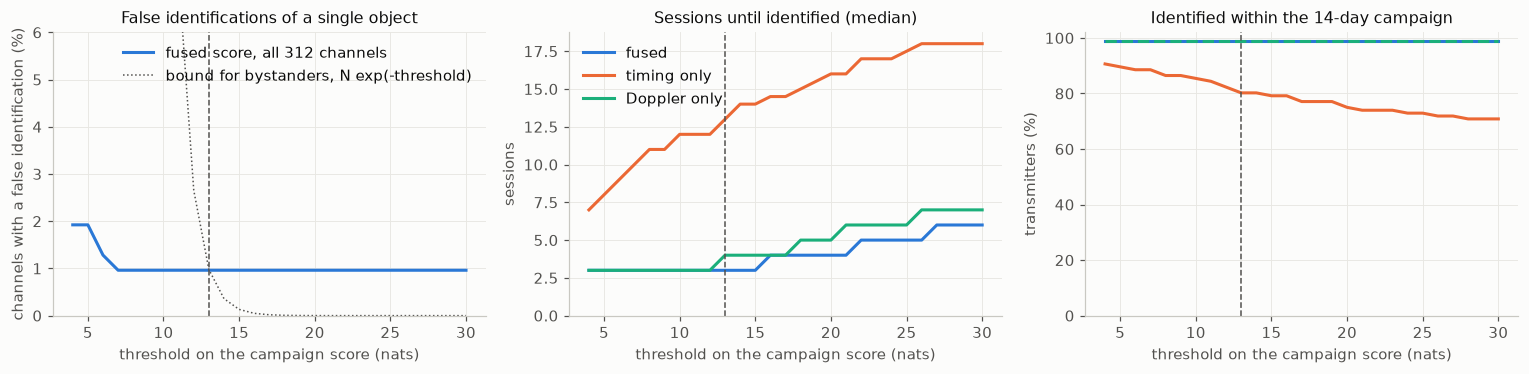

In [14]:
singles = [r for r in MC["single"] if kind(r) != "companions"]
null_like = [r for r in MC["absent"] if kind(r) != "companions"] + MC["multi"] + singles + MC["ground"]
THR = np.arange(4, 30.5, 1.0)
fir = [np.mean([bool(outcome(r, "fused", t)["false_ids"]) for r in null_like]) for t in THR]
tti = {m: [np.median([v[0] for r in singles for v in outcome(r, m, t)["first_true"].values()] or [np.nan]) for t in THR] for m in ("fused", "timing", "doppler")}
found = {m: [np.mean([bool(outcome(r, m, t)["first_true"]) for r in singles]) for t in THR] for m in ("fused", "timing", "doppler")}
thr = L.DecisionConfig(n_candidates=len(C.cat)).threshold

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(THR, 100 * np.array(fir), color=COL[0], label="fused score, all 312 channels")
ax[0].plot(THR, 100 * np.minimum(1, len(C.cat) * np.exp(-THR)), color=MUTED, lw=1, ls=":", label="bound for bystanders, N exp(-threshold)")
for k, (m, lab) in enumerate((("fused", "fused"), ("timing", "timing only"), ("doppler", "Doppler only"))):
    ax[1].plot(THR, tti[m], color=COL[k], label=lab)
    ax[2].plot(THR, 100 * np.array(found[m]), color=COL[k], label=lab, ls="-" if k != 2 else "--")
for a in ax:
    a.axvline(thr, color=MUTED, lw=1, ls="--")
    a.set_xlabel("threshold on the campaign score (nats)")
ax[0].set(ylabel="channels with a false identification (%)", ylim=(0, 6), title="False identifications of a single object")
ax[1].set(ylabel="sessions", ylim=(0, None), title="Sessions until identified (median)")
ax[2].set(ylabel="transmitters (%)", ylim=(0, 102), title="Identified within the 14-day campaign")
ax[0].legend()
ax[1].legend()
plt.tight_layout()
i = int(np.argmin(np.abs(THR - round(thr))))
print(f"fused score at threshold {THR[i]:.0f}: a wrong object passes tests 1-3 in {fir[i]:.1%} of {len(null_like)} channels")
for m in ("fused", "timing", "doppler"):
    print(f"{m:8s} at threshold {THR[i]:.0f}: median {tti[m][i]:.0f} sessions to identify, {found[m][i]:.0%} of {len(singles)} transmitters identified within 14 days")

- **The false identifications do not depend on the threshold.** The two wrong objects that pass have scores of 18 and 37
  nats; raising Λ\* to 30 would not remove them. They are not chance coincidences, which is what the threshold
  guards against, but neighbours, which only tests 3 and 4 and the free-orbit reference can stop. (The sweep counts 3
  channels at Λ\* = 13 where the full rule gives 2: the kin verdict stops the third.) Below 7 nats chance
  coincidences start to appear.
- **Time to identify is flat in the threshold**: 3 sessions up to Λ\* = 15, 5 at Λ\* = 25. The three-session rule,
  not the threshold, is what binds for most transmitters.
- **Doppler carries most of the evidence** for the transmitters simulated here (tracks of 25 s and more): on its own
  it identifies 99 % in a median of 4 sessions. Timing on its own needs 13 sessions and leaves 20 % unidentified
  after two weeks, because objects in similar orbits share sessions. Fusing saves a session and, more importantly,
  is what the kin test and the handling of short bursts rest on.

## 7 · A campaign end to end

Eight transmitters and a ground carrier over two weeks: three zombies on their real frequencies, a fourth sharing its
channel with a burst transmitter 1.2 kHz away, a zombie that is **not in the catalog**, the ISS (nine catalog entries
for one object) and a weak transmitter. Detections are clustered into channels, each channel is scored session by
session, and the verdicts are listed in the order they were reached.

channel MHz  det. sess.  transmitters (truth), then the verdicts in the order they were reached
   136.4104   120    52  OPS 7613 (P/L 1)
                         identified: OPS 7613 (P/L 1) [session 7, day 1.2, 19 nats]
   136.5873   104   104  OPS 6582 (TRANSIT 5B-5)
                         identified: OPS 6582 (TRANSIT 5B-5) [session 4, day 0.7, 14 nats]
   136.6496    27    27  2026-027E (not in catalog)
                         not in catalog [session 6, day 2.5]
   136.7527   493   133  OPS 7613 (P/L 4), GEESAT-1 09
                         identified: OPS 7613 (P/L 4) [session 4, day 0.4, 16 nats]
                         identified: GEESAT-1 09 [session 14, day 1.4, 18 nats]
                         not in catalog [session 32, day 3.4]
   136.8032  1674   133  ALOUETTE 2
                         identified: ALOUETTE 2 [session 4, day 0.3, 26 nats]
   137.1355    36    34  ground carrier
                         not satellite [session 4, day 2.6]
   137.2998    76    76  ISS (

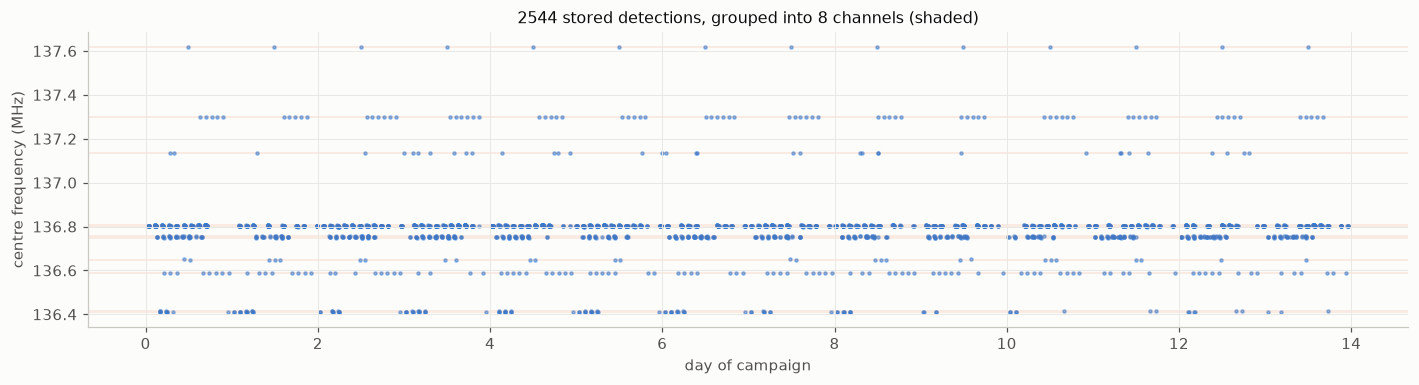

In [15]:
# A two-week campaign on a busy band: eight channels, one of them shared, one object missing from the catalog.
ABSENT = ISOLATED[20]
PLAN = [  # (norad, archetype, rest frequency)
    (4256, "keyed", 136.4118e6), (965, "zombie", 136.5872e6), (4237, "keyed", 136.7524e6), (ISOLATED[12], "burster", 136.7536e6),
    (1804, "wild", 136.8031e6), (ABSENT, "zombie", 136.6500e6), (25544, "beacon", 137.3000e6), (ISOLATED[30], "weak", 137.6200e6),
]  # fmt: skip


def demo_campaign():
    rng = np.random.default_rng(5)
    dets = []
    for norad, prof, f in PLAN:
        dets += C.emulate(norad, prof, f, rng)
    dets += L.ground_carrier(C.t0, C.t1, 137.1355e6, rng)
    out = []
    for cl in L.cluster_by_frequency(dets):
        sessions = L.make_sessions(cl)
        evs = C.evidence(sessions, rng, exclude=(ABSENT,))
        truth = sorted({d.truth for d in cl})
        tr = L.trajectory(C, evs, [n for n in truth if n >= 0 and n != ABSENT], L.DecisionConfig(n_candidates=len(C.cat)))
        out.append(dict(f=np.median([d.fc for d in cl]), f_lo=min(d.fc for d in cl), f_hi=max(d.fc for d in cl), n_dets=len(cl), truth=truth, tr=tr,
                        sessions=[dict(t1=e.t1, cand=e.cand, f_rest=e.f_rest, truth=e.truth) for e in evs]))  # fmt: skip
    return dict(dets=[(d.t0, d.t1, d.fc, d.truth) for d in dets], channels=out)


demo = cached("demo_campaign", demo_campaign)
d = np.array(demo["dets"])
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.scatter((d[:, 0] - C.t0) / 86400, d[:, 2] / 1e6, s=4, color=COL[0], alpha=0.5)
for ch in demo["channels"]:
    ax.axhspan(ch["f_lo"] / 1e6 - 0.004, ch["f_hi"] / 1e6 + 0.004, color=COL[1], alpha=0.12, lw=0)
ax.set(xlabel="day of campaign", ylabel="centre frequency (MHz)", title=f"{len(d)} stored detections, grouped into {len(demo['channels'])} channels (shaded)")
plt.tight_layout()

print(f"{'channel MHz':>11s} {'det.':>5s} {'sess.':>5s}  transmitters (truth), then the verdicts in the order they were reached")
for ch in demo["channels"]:
    seen, said, log = set(), {}, []
    for step, t, vs in zip(ch["tr"]["steps"], ch["tr"]["t"], ch["tr"]["verdicts"], strict=True):
        for kind, members, score, _sup in vs:
            if kind in ("identified", "related") and said.setdefault(members[0], kind) != kind:
                continue  # the first verdict about an object stands
            if (kind, members) not in seen:
                seen.add((kind, members))
                who = " = ".join(C.name(m) for m in members[:3]) + (f" (+{len(members) - 3} more)" if len(members) > 3 else "")
                when = f"session {step}, day {(t - C.t0) / 86400:.1f}"
                log.append(f"{kind.replace('_', ' ')}{': ' + who if who else ''} [{when}" + (f", {score:.0f} nats]" if members else "]"))
    truth = ", ".join(("ground carrier" if n < 0 else C.name(n) + (" (not in catalog)" if n == ABSENT else "")) for n in ch["truth"])
    print(f"{ch['f'] / 1e6:11.4f} {ch['n_dets']:5d} {len(ch['sessions']):5d}  {truth}\n{'':25s}" + (f"\n{'':25s}".join(log) if log else "undecided"))

All eight channels end with the right verdict: six identifications (two of them on the shared channel), the ISS as a
group of its catalog entries, the uncatalogued zombie as `not in catalog` and the ground carrier as `not satellite`.
The shared channel also shows the known false alarm: a `not in catalog` at session 32, from sessions in which the
passes of its two transmitters overlapped.

Once a channel is identified, the implied rest frequency $c_H$ of every session is a by-product: the transmitter's
rest-frequency history, pass by pass.

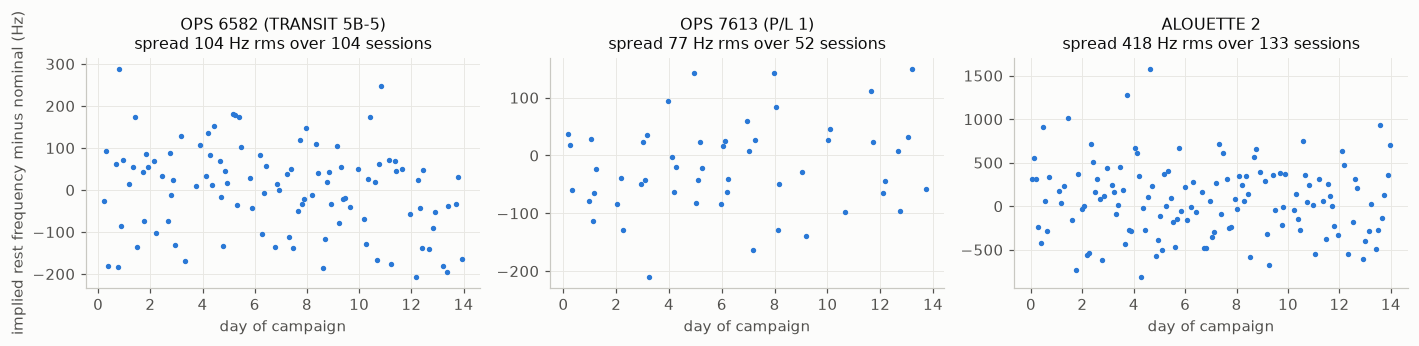

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, (norad, f_nom) in zip(ax, [(965, 136.5872e6), (4256, 136.4118e6), (1804, 136.8031e6)], strict=True):
    ch = min(demo["channels"], key=lambda c: abs(c["f"] - f_nom))
    i = C.cat.index(norad)
    pts = [((s["t1"] - C.t0) / 86400, s["f_rest"][np.flatnonzero(s["cand"] == i)[0]] - f_nom) for s in ch["sessions"] if i in s["cand"] and s["truth"] == norad]
    pts = np.array(pts)
    a.plot(pts[:, 0], pts[:, 1], ".", color=COL[0])
    a.set(xlabel="day of campaign", title=f"{C.name(norad)}\nspread {np.std(pts[:, 1]):.0f} Hz rms over {len(pts)} sessions")
ax[0].set_ylabel("implied rest frequency minus nominal (Hz)")
plt.tight_layout()

The spread is what the simulator injected (80 Hz pass to pass plus thermal drift for the first two, 300 Hz plus jumps
for the ALOUETTE-like one). On real data this series answers the open question of the brief, whether a zombie's rest
frequency is repeatable, and if it is, it becomes a third source of evidence (see the open points).

## 8 · Findings and open points

Numbers are from 14 simulated days, 60 transmitters, 360 channel-campaigns scored session by session.

**The method**

| Step | What it does | Result |
|---|---|---|
| Candidates | nearest-epoch element set, dopplerguesser's filters, visible for the whole signal | 4321 objects; ~230 candidates for a 20 s signal, ~50 for 10 min |
| Timing evidence | 1/q: how rarely the object is up for a signal of this length | ~3 nats per session; silence never enters |
| Doppler evidence | robust fit with a transmitter model, against 500 decoys and a freely fitted orbit | true satellite first in 66–100 % of sessions; bystanders average ℓ ≤ 1 |
| Fusion | mixture of transmitters per channel; score = improvement from adding the candidate | several transmitters per channel work; twins cancel into a group |
| Decision | score ≥ ln(N/α) = 13 nats, 3 sessions, Doppler confirmation, kin test | 0 false in 210 channels with the transmitter catalogued; 2 in 96 without |

**What the simulations say**

- Robust loss: least squares misidentifies 34 % / 58 % of 90 s tracks at 3 % / 10 % bad bins; Student-t and clipped χ²
  at most 0.4 % up to 50 %.
- Track length: the true satellite is not ranked first in 33 % of 10 s, 20 % of 20 s and 1.5 % of 90 s tracks.
- Oscillators: what each behaviour needs is a term in the transmitter model: steps for jumps (every jump is a new
  detection), two exponential tails for the droop, bounded wander for thermal drift, and effective-sample-size
  scaling for random wander.
- Element sets: 1 s of along-track error costs nothing, 4 s loses 30 % of the long passes.
- Time to identify: 3 sessions for one long track per pass, 6 for keyed or burst transmitters, 10 on a shared
  channel. The three-session rule binds, not the threshold.
- The threshold protects against chance; the false identifications that remain are neighbours and do not go away at
  any threshold.

**What I have not verified**

- **Real signals.** Everything is simulated, and the oscillator magnitudes are assumptions; only the droop shape comes
  from a real pass. The transmitter model was built against the same behaviours the simulator injects (with different
  constants). Real zombies will have behaviours neither contains.
- **The tracker emulator.** It uses the numbers measured in notebooks 0 and 1, not their code. In particular it
  assumes a jump always ends a track cleanly; a tracker that follows part of a jump would hand the fit a step inside
  a detection, which the model does not have.
- **The 1 % claim.** 0 false in 210 channels bounds the rate at about 1.4 % (95 %); it does not show 1 %. The
  martingale argument covers bystanders only, and the refitted rival mixture makes even that approximate.
- **Thresholds of tests 3 and 4, the session cap and the wander and along-track priors** were set on test channels
  drawn from the same pool as the final Monte-Carlo. There is no hold-out pool.
- **Short bursts.** The burst archetype has 32–45 s bursts. A transmitter with only 10–20 s bursts will rarely pass
  Doppler confirmation and would stay undecided; not simulated at campaign level.
- **Other stations and seasons.** One station (55.5° N), two weeks in November.

**Known weaknesses**

1. **Neighbours when the transmitter is not catalogued.** 2 false identifications and 4 false groups in 58 train
   channels, and the companion is named in 18 of 24 companion channels. If the candidate catalog is filtered (it
   drops 12 000 objects) this case is not exotic.
2. **Overlapping passes on a shared channel** merge into one session that no candidate explains. This costs
   identifications (131 of 140), and produced a wrong `related` in 6 and a wrong `not in catalog` in 2 of 60 shared
   channels. Sessions need to be split by frequency continuity, or a candidate allowed to explain part of a session.
3. **False groups.** A group is assembled from the rivals that take over a candidate's sessions; when the transmitter
   is absent this can gather unrelated train members. Requiring every member to explain nearly all of the same
   sessions would be stricter; not tested.
4. **`not in catalog` is a counting rule**, not a likelihood: five informative, unexplained sessions making up a
   third of the channel. It works here (92 of 96) but has no error bound.
5. **Stale elements.** Beyond about 2 s of along-track error the free-orbit reference turns long passes against the
   true satellite. With space-track GP history this should not occur; with weekly snapshots it will.
6. **Cost.** About 0.6 s per session in numpy including the re-scoring after every session; most of it is the free-orbit fit and the 500 decoys. Fine for a station
   (hundreds of sessions a day), slow for Monte-Carlo.

**Decisions for you**

- **Element-set source.** The method assumes element sets within a day or so of each detection. Is space-track GP
  history available to the real system from the start?
- **What to do with `related`, `ambiguous` and companions.** They are honest outputs, but a catalog of zombies needs
  a policy: report the group, or resolve it by other means (launch date, known frequencies, SatNOGS).
- **Whether the filtered objects should be candidates after all.** A transmitter on a Starlink or a rocket body is
  "not in catalog" by construction of the filter, and it is the not-in-catalog case that produces the errors.

**Suggested next steps**

1. Run the fit on the real passes you have (the `droop.png` pass and any others): it will show at once whether the
   transmitter model leaves structure in the residuals, and gives the first real rest-frequency series.
2. Split merged sessions by frequency continuity (weakness 2).
3. If rest frequencies turn out repeatable from pass to pass, add the agreement of $c_H$ across sessions as a third
   likelihood ratio; it is independent of both timing and Doppler shape and would separate train neighbours.
4. Fit the along-track offset as a per-object constant over the campaign instead of per session: a neighbour needs
   the same large offset every time, a stale element set a slowly growing one, the true satellite none.
5. Wire the real `0_detection` → `1_tracking` output into `Session`, and measure the whole chain on rendered IQ for a
   few passes.